# NN_L10_dp_value

**Value function V_h(s) of the battery problem on one real day: the euros still to be earned from hour h with s MWh stored (the shadow price of stored energy).**

Neural Networks and Deep Learning (NN), Lecture 10 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L10/NN_L10_dp_value/NN_L10_dp_value.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

V_12(0) (EUR) = 1541.0   [day.v12_s0]
V_12(2) (EUR) = 1760.0   [day.v12_s2]


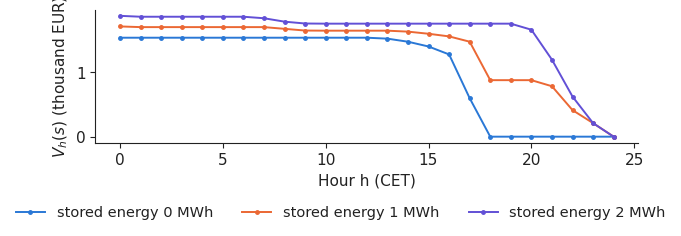

In [3]:
import torch, torch.nn as nn
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
END = '2026-10-31'                                   # last complete month of the course data
x = x.loc[:END + ' 23:59']
x['day'] = x.index.tz_localize(None).normalize(); x['hour'] = x.index.hour
def day_matrix(zone):
    d = x[['day', 'hour', zone]].dropna(); n = d.groupby('day')[zone].count()
    return d[d.day.isin(n[n == 24].index)].pivot_table(index='day', columns='hour', values=zone).sort_index()
RO = day_matrix('RO')
E_MAX, ETA = 2, 0.85
ETA_C = ETA_D = np.sqrt(ETA); ACTS = np.array([-1, 0, 1])
def reward(p, a): return np.where(a > 0, ETA_D * p, np.where(a < 0, -p / ETA_C, 0.0))
def dp_days(P):
    D = P.shape[0]; V = np.zeros((D, 25, E_MAX + 1)); A = np.zeros((D, 24, E_MAX + 1), dtype=int)
    for h in range(23, -1, -1):
        best = np.full((D, E_MAX + 1), -np.inf); arg = np.zeros((D, E_MAX + 1), dtype=int)
        for s in range(E_MAX + 1):
            for a in ACTS:
                if 0 <= s - a <= E_MAX:
                    q = reward(P[:, h], a) + V[:, h + 1, s - a]; b = q > best[:, s]; best[b, s] = q[b]; arg[b, s] = a
        V[:, h] = best; A[:, h] = arg
    return V, A
V, A = dp_days(RO.values)
r26 = RO.loc['2026']; day = (r26.max(axis=1) - r26.min(axis=1)).idxmax(); di = RO.index.get_loc(day)
show('day.v12_s0', 'V_12(0) (EUR)', round(float(V[di, 12, 0]), 0))
show('day.v12_s2', 'V_12(2) (EUR)', round(float(V[di, 12, 2]), 0))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for s_, c in zip(range(3), (PAL['data'], PAL['model'], '#6250d6')):
    ax.plot(range(25), V[di, :, s_] / 1000, marker='o', ms=2.5, color=c, label=f'stored energy {s_} MWh')
ax.set_xlabel('Hour h (CET)'); ax.set_ylabel('$V_h(s)$ (thousand EUR)'); legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('dp_value.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()